# 05. 方差分解

本 notebook 评估 ACRs、UMRs、proximal TEs、它们的 union 以及 genome-wide reference 的 context-specific genomic relationship matrices，并将 GSL spatial panel 与 LDAK REML 结果合并生成 Figure 4。


In [1]:
import os
import pandas as pd
import warnings
warnings.filterwarnings('ignore')

data_dir = os.path.join(os.getcwd(), "data")
source_dir = os.path.join(data_dir, "source")
results_dir = os.path.join(data_dir, "results")
run_dir = os.path.join(os.getcwd(), "run")

partition_dir = os.path.join(results_dir, "partition")
os.makedirs(partition_dir, exist_ok=True)

载入landraces信息

In [2]:
vcf_file = os.path.join(data_dir, "source", "landraces_GxE_miss0.5_maf0.05_het0.05.vcf.gz")
landraces_prune_vcf_file = os.path.join(data_dir, "source", "landraces_snp_pruned.win15000.miss0.5.maf0.01.het0.01.rq0.5.vcf.gz")
landraces_df = pd.read_csv(os.path.join(data_dir, "source", "landraces_metadata.csv"))

载入具有GxE表型的样本信息

In [3]:
phenotypes_df = pd.read_csv(os.path.join(data_dir, "source", "Bernardino_2024_GxE_phenotypes.csv"))
predict_sample_ids = phenotypes_df['LIB'].tolist()

载入contexts设定

In [4]:
site_context_df = pd.read_hdf(os.path.join(data_dir, "results", "site_contexts.genome.maf0.05.h5"), key="df")
site_context_df['genome'] = True

载入envGWAS结果

In [5]:
import numpy as np

env_id_list = ["bio18", "gsl", "al", "striga"]
env_metadata_df = pd.read_csv(os.path.join(data_dir, "source", "envir_metadata.csv"))
env_labels = {}
for env_id in env_id_list:
    env_df = pd.read_hdf(os.path.join(data_dir, "results", "gwas", env_id, f"{env_id}.gemma", f"{env_id}.gemma.gwas_df.h5"), key="df")
    env_df = env_df[['ID', 'P_WALD']]
    env_df = env_df.rename(columns={'P_WALD': env_id})
    env_df[env_id] = -np.log10(env_df[env_id])
    site_context_df = site_context_df.merge(env_df, on='ID', how='left')
    env_labels[env_id] = env_metadata_df.loc[env_metadata_df['env_id'] == env_id, 'description'].values[0]

载入contrasts设定

In [7]:
import json

contrasts_settings_json_file = os.path.join(os.getcwd(), "config", "contrasts_settings.json")
with open(contrasts_settings_json_file, "r") as f:
    contrasts_settings = json.load(f)

向site_context_df中增加Pi、Recomb、MAF等信息

## 1. Genomic compartments

### 1.1 genic_2kb_vs_genome

In [7]:
from src.partition import run_partition_contrast

contrast_id = "genic_2kb_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[genic_2kb_vs_genome] Final outputs already exist, skipping contrast.


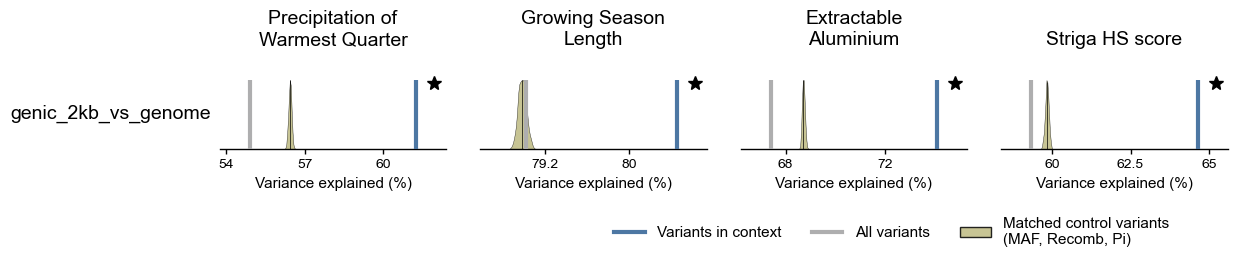

In [8]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

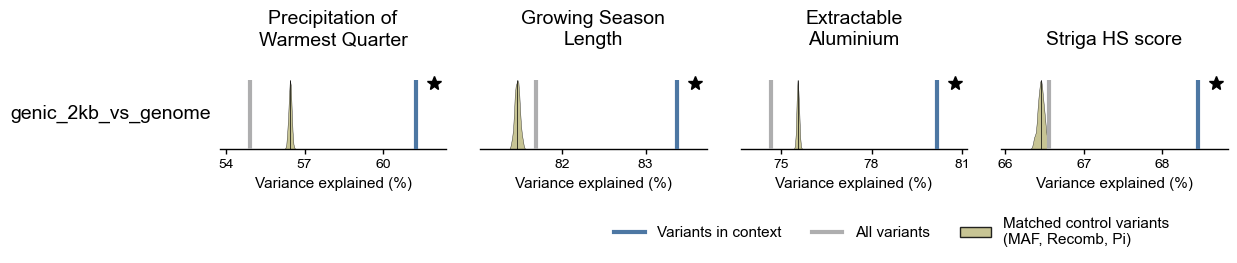

In [9]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [10]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using genic_2kb_vs_genome:
  Genome-wide score: r = 0.280, p = 1.780e-04
  Feature score: r = 0.279, p = 1.823e-04
  Permutation score: mean r = 0.264, std r = 0.000


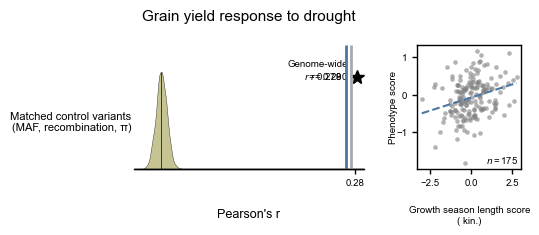

In [11]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

## 2. Gene Structure

### 2.1 在基因区内部比较

#### 2.1.1 upstream_2kb_vs_genic

In [12]:
from src.partition import run_partition_contrast

contrast_id = "upstream_2kb_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[upstream_2kb_vs_genic] Final outputs already exist, skipping contrast.


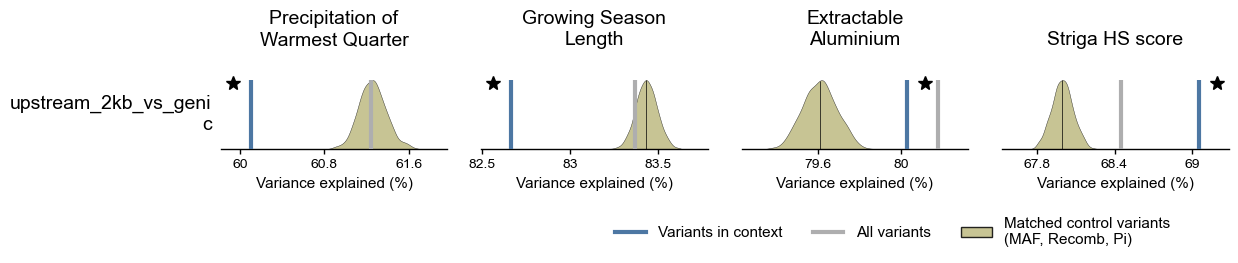

In [13]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [14]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using upstream_2kb_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.271, p = 2.919e-04
  Permutation score: mean r = 0.275, std r = 0.001


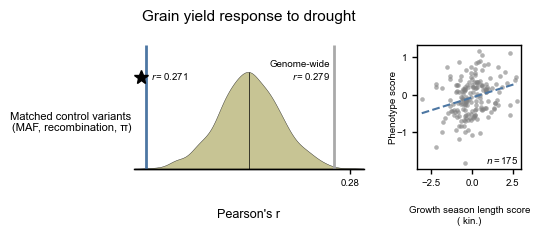

In [15]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 2.1.2 five_prime_UTR_vs_genic

In [16]:
from src.partition import run_partition_contrast

contrast_id = "five_prime_UTR_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[five_prime_UTR_vs_genic] Final outputs already exist, skipping contrast.


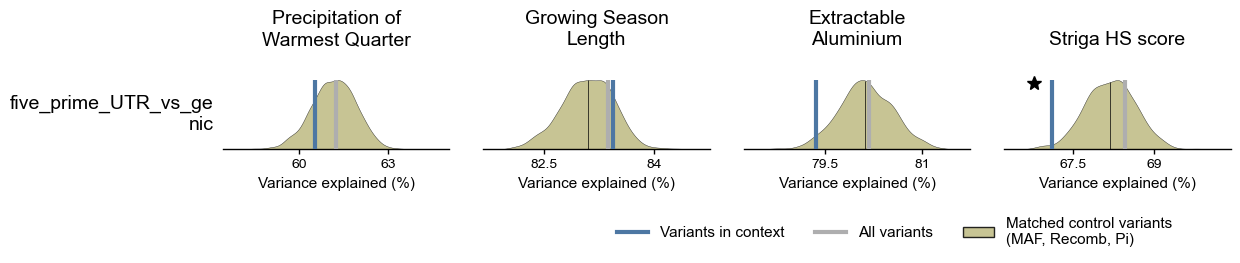

In [17]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [18]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using five_prime_UTR_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.241, p = 1.316e-03
  Permutation score: mean r = 0.282, std r = 0.008


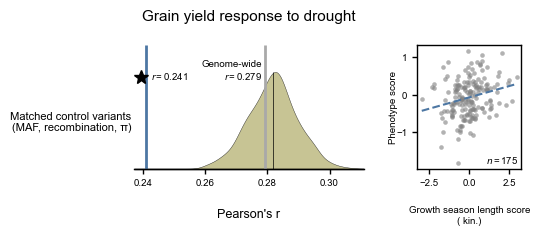

In [19]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 2.1.3 CDS_vs_genic

In [20]:
from src.partition import run_partition_contrast

contrast_id = "CDS_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[CDS_vs_genic] Final outputs already exist, skipping contrast.


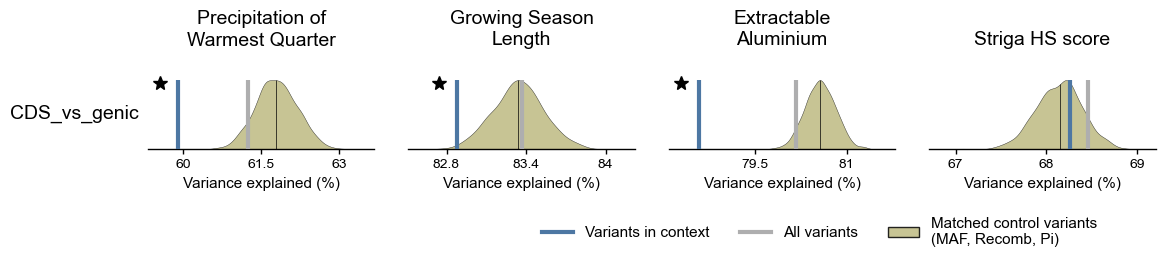

In [21]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [22]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using CDS_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.275, p = 2.251e-04
  Permutation score: mean r = 0.289, std r = 0.005


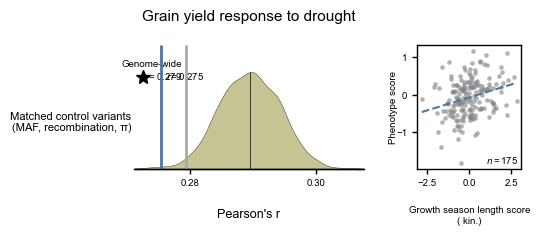

In [23]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 2.1.4 intron_vs_genic

In [24]:
from src.partition import run_partition_contrast

contrast_id = "intron_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[intron_vs_genic] Final outputs already exist, skipping contrast.


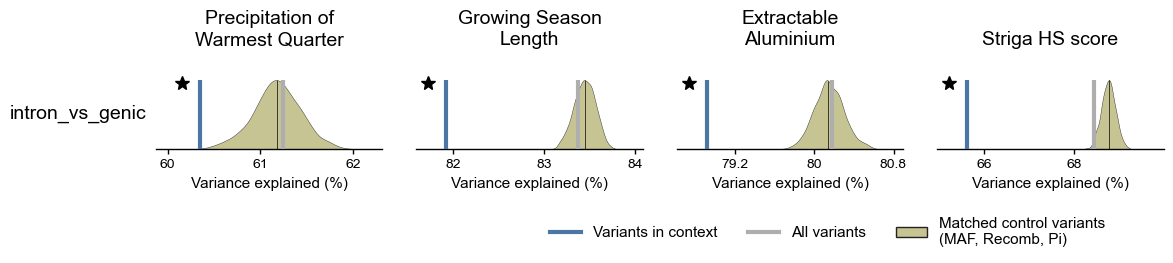

In [25]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [26]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using intron_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.300, p = 5.613e-05
  Permutation score: mean r = 0.276, std r = 0.003


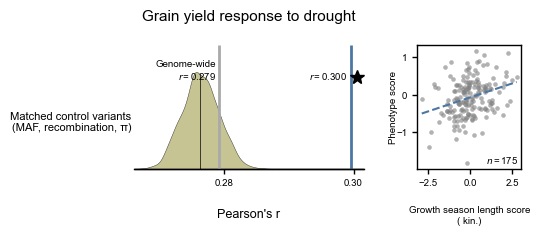

In [27]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 2.1.5 three_prime_UTR_vs_genic

In [28]:
from src.partition import run_partition_contrast

contrast_id = "three_prime_UTR_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[three_prime_UTR_vs_genic] Final outputs already exist, skipping contrast.


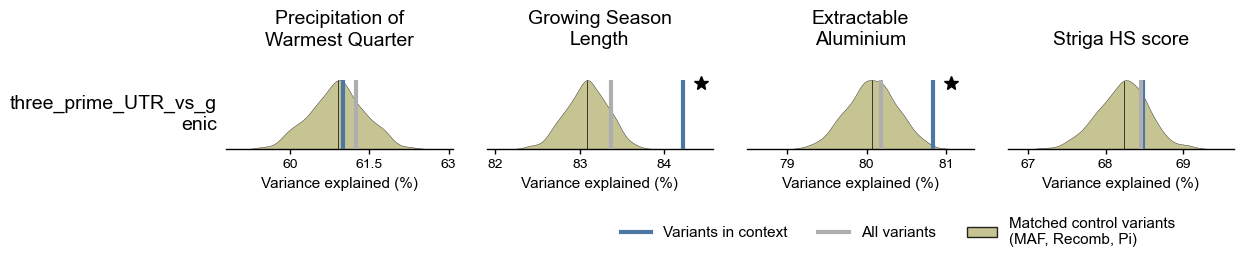

In [29]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [30]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using three_prime_UTR_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.267, p = 3.463e-04
  Permutation score: mean r = 0.278, std r = 0.006


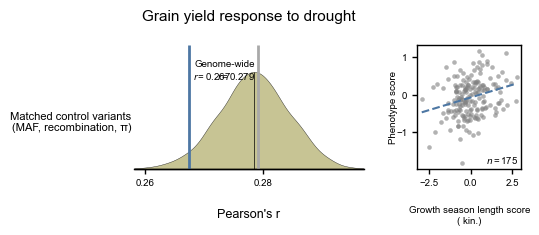

In [31]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 2.1.6 downstream_2kb_vs_genic

In [32]:
from src.partition import run_partition_contrast

contrast_id = "downstream_2kb_vs_genic"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[downstream_2kb_vs_genic] Final outputs already exist, skipping contrast.


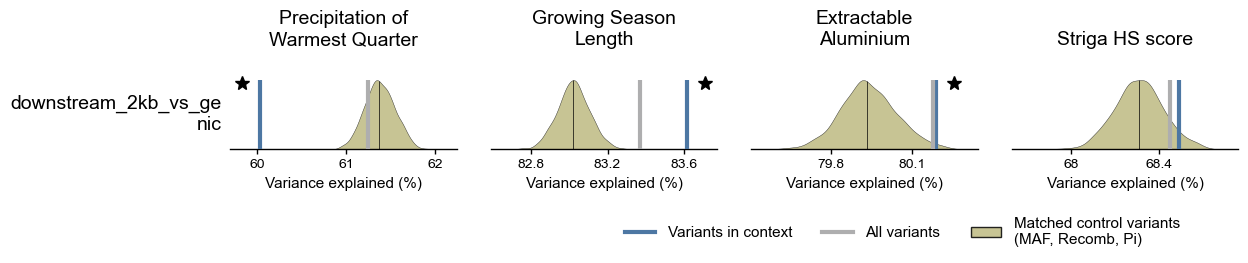

In [33]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [34]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using downstream_2kb_vs_genic:
  Genome-wide score: r = 0.279, p = 1.823e-04
  Feature score: r = 0.276, p = 2.134e-04
  Permutation score: mean r = 0.275, std r = 0.002


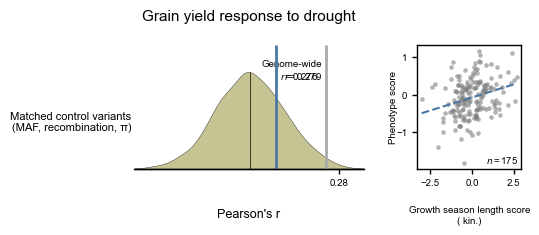

In [35]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

## 3. Epigenomic features

### 3.1 ACR_vs_genome

In [36]:
from src.partition import run_partition_contrast

contrast_id = "ACR_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[ACR_vs_genome] Final outputs already exist, skipping contrast.


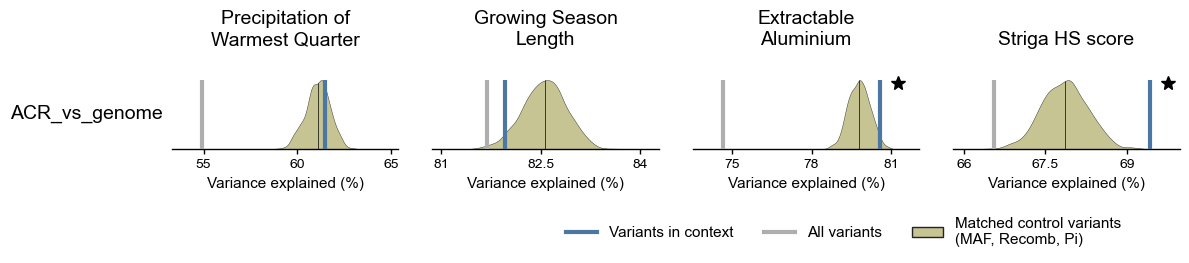

In [37]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [38]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using ACR_vs_genome:
  Genome-wide score: r = 0.280, p = 1.780e-04
  Feature score: r = 0.290, p = 9.729e-05
  Permutation score: mean r = 0.272, std r = 0.007


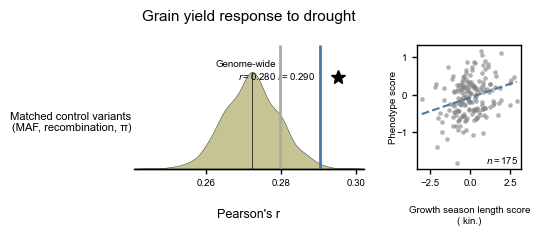

In [ ]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 3.2 UMR_vs_genome

In [40]:
from src.partition import run_partition_contrast

contrast_id = "UMR_vs_genome"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[UMR_vs_genome] Final outputs already exist, skipping contrast.


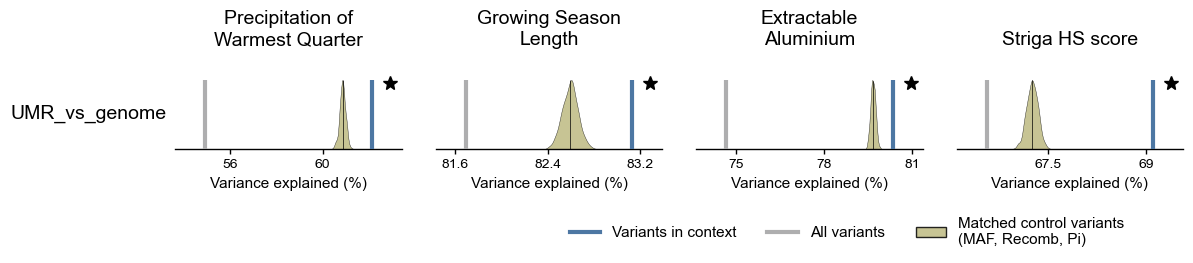

In [41]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [42]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using UMR_vs_genome:
  Genome-wide score: r = 0.280, p = 1.780e-04
  Feature score: r = 0.275, p = 2.319e-04
  Permutation score: mean r = 0.270, std r = 0.001


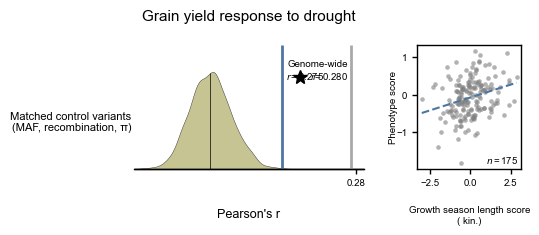

In [43]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

## 4. Genic proximal and distal

### 4.1 proximal_TE_vs_proximal

In [44]:
from src.partition import run_partition_contrast

contrast_id = "proximal_TE_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[proximal_TE_vs_proximal] Final outputs already exist, skipping contrast.


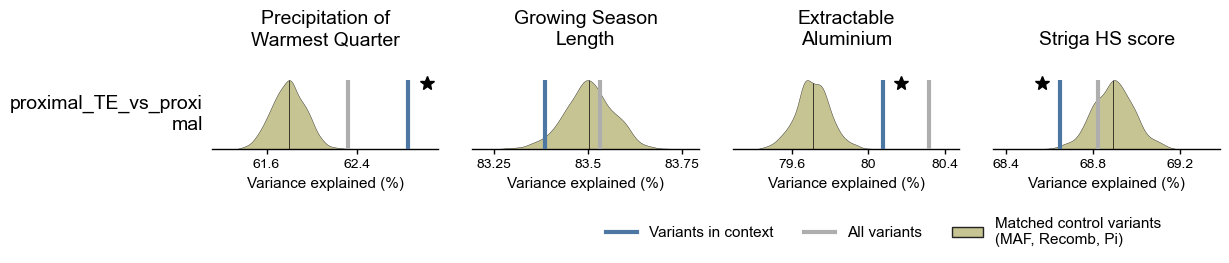

In [45]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [46]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using proximal_TE_vs_proximal:
  Genome-wide score: r = 0.278, p = 1.981e-04
  Feature score: r = 0.289, p = 1.060e-04
  Permutation score: mean r = 0.267, std r = 0.002


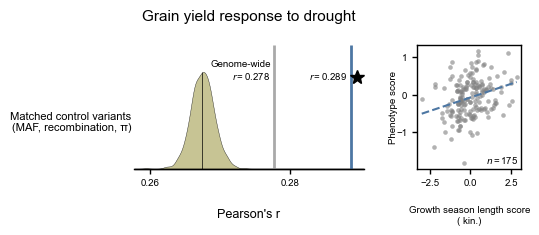

In [47]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.3 proximal_ACR_vs_proximal

In [48]:
from src.partition import run_partition_contrast

contrast_id = "proximal_ACR_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[proximal_ACR_vs_proximal] Final outputs already exist, skipping contrast.


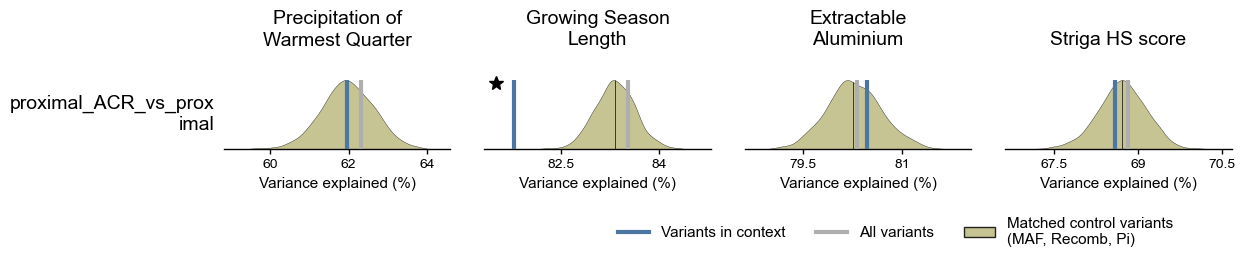

In [49]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [50]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using proximal_ACR_vs_proximal:
  Genome-wide score: r = 0.278, p = 1.981e-04
  Feature score: r = 0.296, p = 7.101e-05
  Permutation score: mean r = 0.275, std r = 0.008


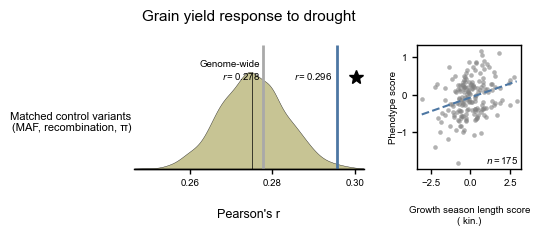

In [51]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.4 distal_ACR_vs_distal

In [52]:
from src.partition import run_partition_contrast

contrast_id = "distal_ACR_vs_distal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[distal_ACR_vs_distal] Final outputs already exist, skipping contrast.


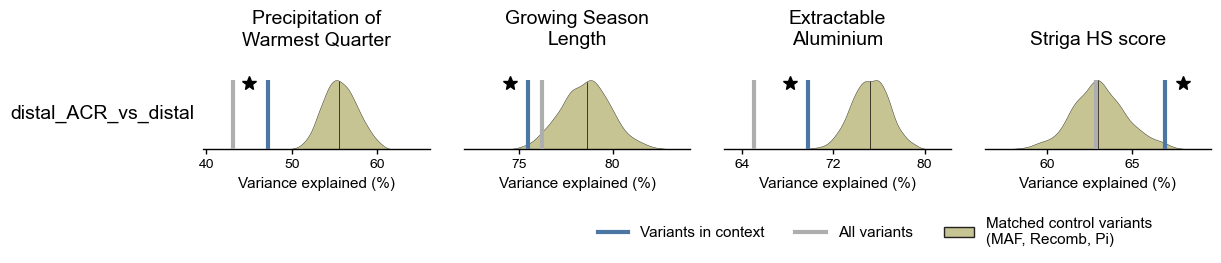

In [53]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [54]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using distal_ACR_vs_distal:
  Genome-wide score: r = 0.241, p = 1.322e-03
  Feature score: r = 0.210, p = 5.387e-03
  Permutation score: mean r = 0.226, std r = 0.020


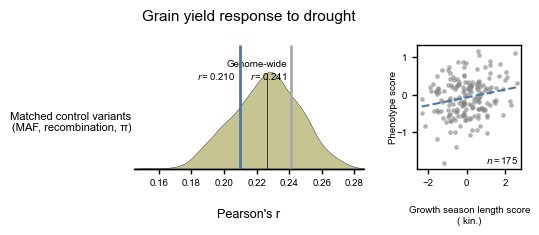

In [55]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.5 proximal_UMR_vs_proximal

In [56]:
from src.partition import run_partition_contrast

contrast_id = "proximal_UMR_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[proximal_UMR_vs_proximal] Final outputs already exist, skipping contrast.


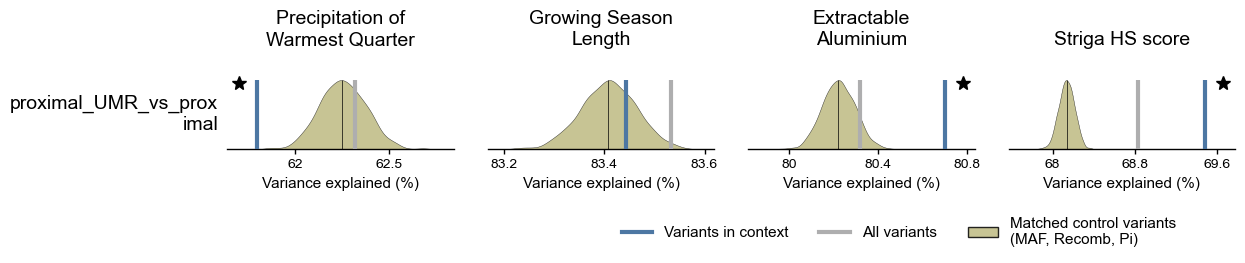

In [57]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [58]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using proximal_UMR_vs_proximal:
  Genome-wide score: r = 0.278, p = 1.981e-04
  Feature score: r = 0.274, p = 2.458e-04
  Permutation score: mean r = 0.275, std r = 0.001


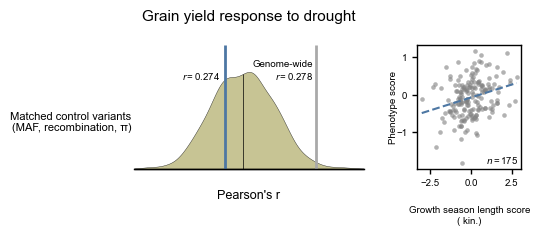

In [59]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.6 distal_UMR_vs_distal

In [60]:
from src.partition import run_partition_contrast

contrast_id = "distal_UMR_vs_distal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[distal_UMR_vs_distal] Final outputs already exist, skipping contrast.


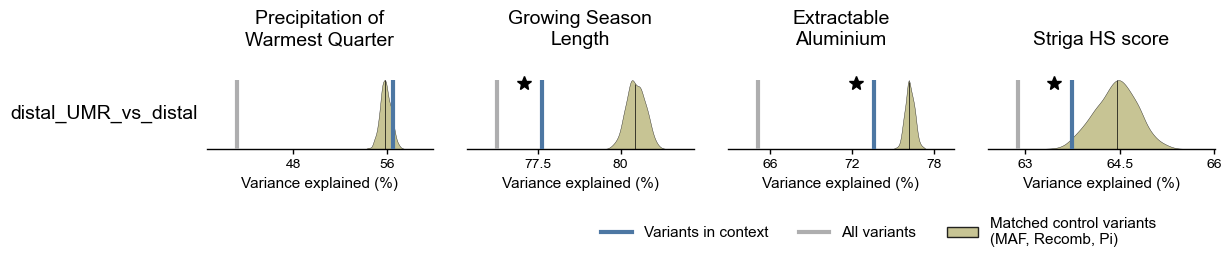

In [61]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [62]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using distal_UMR_vs_distal:
  Genome-wide score: r = 0.241, p = 1.322e-03
  Feature score: r = 0.256, p = 6.363e-04
  Permutation score: mean r = 0.237, std r = 0.004


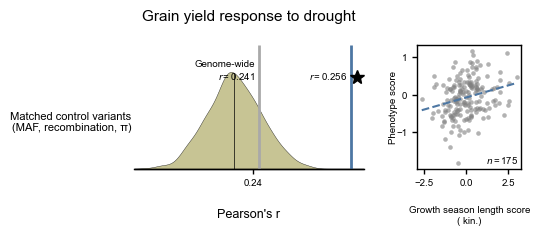

In [63]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.7 proximal_ACR_not_TE_vs_proximal_TE_not_ACR

In [64]:
from src.partition import run_partition_contrast

contrast_id = "proximal_ACR_not_TE_vs_proximal_TE_not_ACR"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[proximal_ACR_not_TE_vs_proximal_TE_not_ACR] Final outputs already exist, skipping contrast.


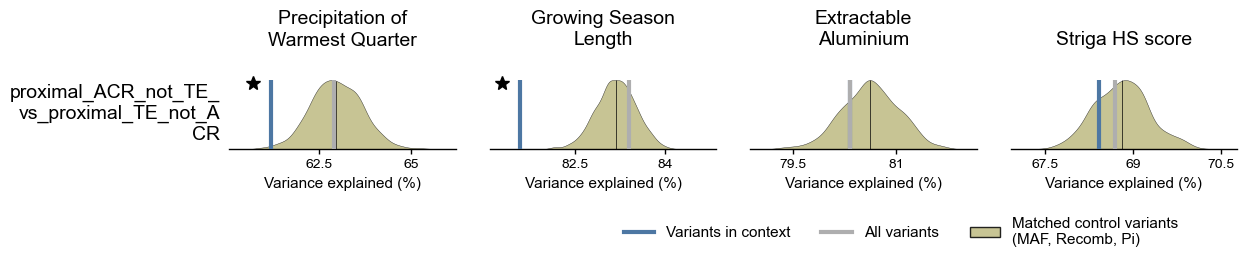

In [65]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [66]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using proximal_ACR_not_TE_vs_proximal_TE_not_ACR:
  Genome-wide score: r = 0.291, p = 9.416e-05
  Feature score: r = 0.301, p = 5.086e-05
  Permutation score: mean r = 0.287, std r = 0.008


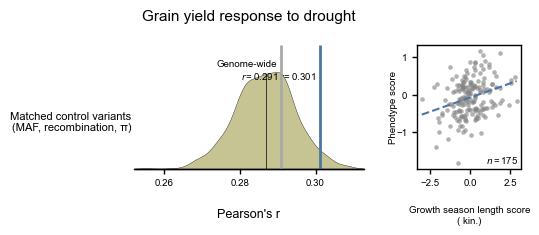

In [67]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

### 4.8 proximal_ACR_TE_UMR_vs_proximal

In [7]:
from src.partition import run_partition_contrast

contrast_id = "proximal_ACR_TE_UMR_vs_proximal"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42
# Choose exactly one non-default mode manually when needed:
#   use_complement=True: analyze the original foreground's complement
#   sample_from_all_sites=True: sample matched controls from all sites
use_complement=False
sample_from_all_sites=False

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto",
                       use_complement=use_complement, sample_from_all_sites=sample_from_all_sites)


[proximal_ACR_TE_UMR_vs_proximal] Building matched variant sets...


Generating matched variant sets:   0%|          | 0/1000 [00:00<?, ?it/s]


ValueError: PERM_0: fallback pool too small (need=1,141,772, available=664).

## 5. Evolutionary conservation & Population genetics

### 5.3 Phylogenetic conservation (PhyloP)

#### 5.3.2 conserved_sites

In [68]:
from src.partition import run_partition_contrast

contrast_id = "conserved_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[conserved_sites] Final outputs already exist, skipping contrast.


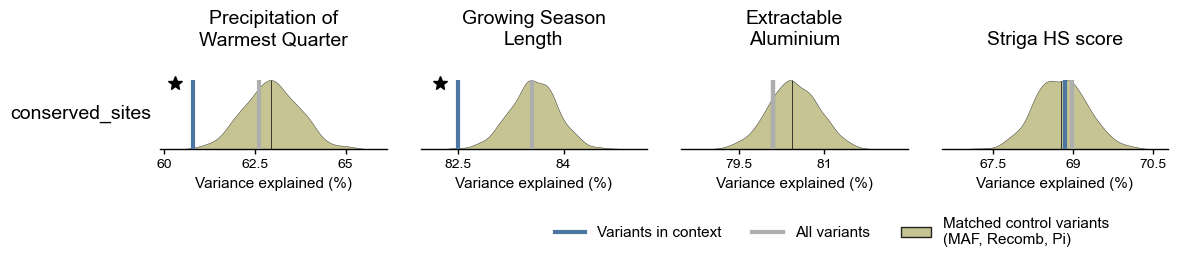

In [69]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [70]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using conserved_sites:
  Genome-wide score: r = 0.277, p = 2.118e-04
  Feature score: r = 0.279, p = 1.855e-04
  Permutation score: mean r = 0.281, std r = 0.008


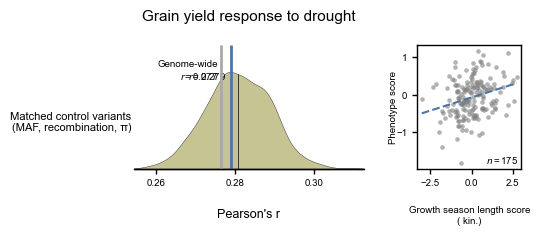

In [71]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 5.3.3 neutral_sites

In [72]:
from src.partition import run_partition_contrast

contrast_id = "neutral_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[neutral_sites] Final outputs already exist, skipping contrast.


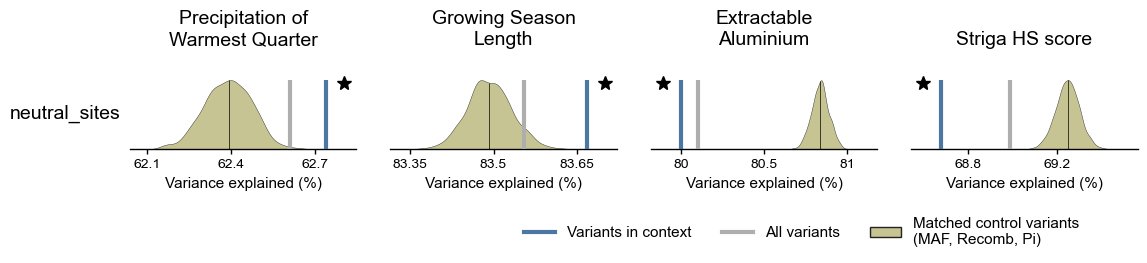

In [73]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [74]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using neutral_sites:
  Genome-wide score: r = 0.277, p = 2.118e-04
  Feature score: r = 0.270, p = 3.019e-04
  Permutation score: mean r = 0.274, std r = 0.001


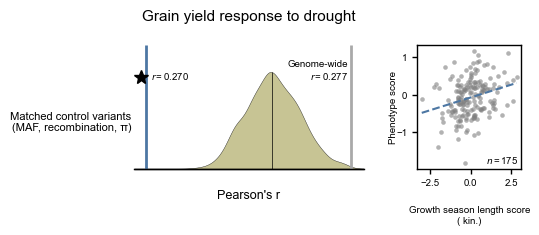

In [75]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                

#### 5.3.4 accelerated_sites

In [76]:
from src.partition import run_partition_contrast

contrast_id = "accelerated_sites"
contrast_json = contrasts_settings[contrast_id]
context_df = site_context_df.copy()
contrast_dir = os.path.join(partition_dir, f"{contrast_id}")

match_controls=("MAF", "Recomb", "Pi")
n_perm=1000
seed=42

_ = run_partition_contrast(contrast_id, contrast_json, context_df, landraces_df, env_id_list,
                       predict_sample_ids, vcf_file, contrast_dir, match_controls = match_controls, n_perm=n_perm, seed=seed,
                       pruned_vcf_file=landraces_prune_vcf_file, n_pcs="auto")


[accelerated_sites] Final outputs already exist, skipping contrast.


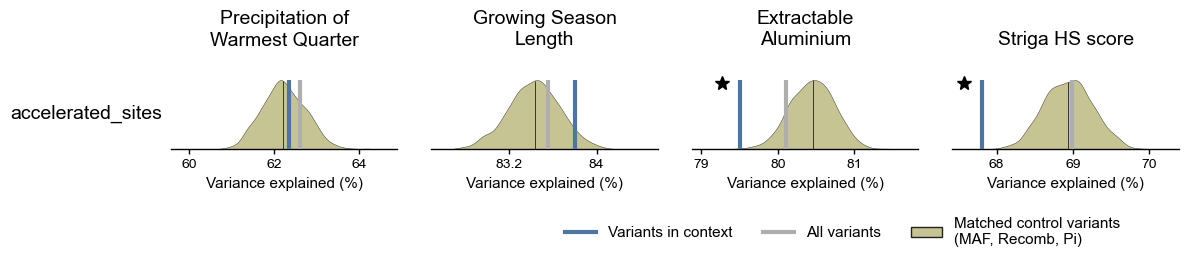

In [77]:
from src.enrich import two_sided_empirical_pvalue
from src.partition import plot_variance_explained

feature_labels = {contrast_id:contrast_id}

reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_unadjusted.csv"))
# reml_results_df = pd.read_csv(os.path.join(contrast_dir, "final", "reml_summary_pc_adjusted.csv"))
# reml_results_df = pd.read_csv("/lustre/home/dobby/Work/Project/functional-genomic-local-adaptation-sorghum/data/results/partition/ACR_vs_genome/_work/grms/reml/reml_summary.csv")
reml_results = {}
for env_id in env_id_list:
    fg_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'FOREGROUND'), 'heritability'].values[0]
    genome_heritability = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (reml_results_df['set'] == 'ALL_SITE'), 'heritability'].values[0]
    permutation_heritability_list = reml_results_df.loc[(reml_results_df['phenotype'] == env_id) & (~reml_results_df['perm_index'].isna()), 'heritability'].values.tolist()
    stats = two_sided_empirical_pvalue(fg_heritability, permutation_heritability_list)
    reml_results[env_id] = {
        contrast_id: {
            "foreground_heritability": fg_heritability,
            "genome_heritability": genome_heritability,
            "permutation_heritability_list": permutation_heritability_list,
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }
    }

fig, axes = plot_variance_explained(
    reml_results,
    env_order=env_id_list,
    feature_order=[contrast_id],
    env_labels=env_labels,
    feature_labels=feature_labels,
    control_legend_label=f"Matched control variants\n({', '.join(match_controls)})",
)

In [78]:
from scipy.stats import pearsonr
from src.partition import plot_prediction_performance

target_phenotypes = ["Grain_yield_plast"]
features = [contrast_id]
env_id = 'gsl'
genetic_score_df = pd.read_csv(os.path.join(contrast_dir, "final", "score_summary.csv"))
genetic_score_df = genetic_score_df[genetic_score_df['phenotype'] == env_id]

predict_results = {}
for target_phenotype in target_phenotypes:
    predict_results[target_phenotype] = {}
    for feature in features:
        # All sites genetic score
        all_sites_df = genetic_score_df[genetic_score_df['set'] == "ALL_SITE"][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(all_sites_df, on='LIB', how='left').dropna()
        genome_r, genome_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Feature genetic score
        foreground_df = genetic_score_df[genetic_score_df['set'] == 'FOREGROUND'][['LIB', 'Genetics']].copy()
        target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
        target_phenotypes_df = target_phenotypes_df.merge(foreground_df, on='LIB', how='left').dropna()
        foreground_prediction_df = target_phenotypes_df.copy()
        feature_r, feature_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])

        # Permutation genetic score
        permutation_r_list = []
        for perm_index in range(1000):
            permutation_df = genetic_score_df[(genetic_score_df['set'] == f'PERM_{perm_index}')][['LIB', 'Genetics']].copy()
            target_phenotypes_df = phenotypes_df[['LIB', target_phenotype]].dropna().copy()
            target_phenotypes_df = target_phenotypes_df.merge(permutation_df, on='LIB', how='left').dropna()
            perm_r, perm_p = pearsonr(target_phenotypes_df[target_phenotype], target_phenotypes_df['Genetics'])
            permutation_r_list.append(perm_r)

        stats = two_sided_empirical_pvalue(feature_r, permutation_r_list)
        predict_results[target_phenotype][feature] = {
            "environment": "Growth season length",
            "genome_r": genome_r,
            "genome_p": genome_p,
            "foreground_r": feature_r,
            "foreground_p": feature_p,
            "permutation_r_list": permutation_r_list,
            "genetic_score": foreground_prediction_df['Genetics'].to_numpy(),
            "phenotype_score": foreground_prediction_df[target_phenotype].to_numpy(),
            "direction": 'right' if stats['obs_value'] >= stats['mean_perm'] else 'left',
            "p_value": stats['pval']
        }

        print(f"Prediction performance for {target_phenotype} using {feature}:")
        print(f"  Genome-wide score: r = {genome_r:.3f}, p = {genome_p:.3e}")
        print(f"  Feature score: r = {feature_r:.3f}, p = {feature_p:.3e}")
        print(f"  Permutation score: mean r = {np.mean(permutation_r_list):.3f}, std r = {np.std(permutation_r_list):.3f}")

Prediction performance for Grain_yield_plast using accelerated_sites:
  Genome-wide score: r = 0.277, p = 2.118e-04
  Feature score: r = 0.270, p = 2.969e-04
  Permutation score: mean r = 0.271, std r = 0.005


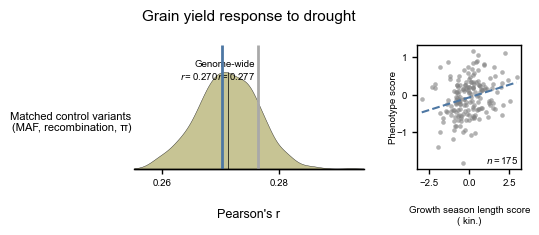

In [79]:
fig, axes = plot_prediction_performance(
    predict_results,
    phenotype_order=[
        "Grain_yield_plast",
    ],
    feature_order=[
        contrast_id,
    ],
    phenotype_labels={
        "Grain_yield_plast":
            "Grain yield response to drought",
    },
    feature_labels={
        contrast_id: "",
    },
    environment_labels={
        "gsl": "Grow. seas. length",
    },
)                